**1. One classifier is not enough. Why can one image classifier not read a whole label such as COFFEE-55? What changes between reading 7, B00K and COFFEE-55?**
A basic classifier only gives one result for the whole picture. Words like "COFFEE-55" are long sequences of letters, and we do not know their length. Reading "7" is just finding one class, but reading "COFFEE-55" is finding a sequence (Shi, Introduction).

**2. Who does what. In a CRNN reader, what job does each part do: the CNN, the BiLSTM and CTC? Why do we still need a text detector for a full photograph?**
The CNN finds visual features from the pixels (Shi, Abstract and architecture). The BiLSTM understands the context of these features (Shi, Abstract and architecture). The CTC changes this into text (Shi, Abstract and architecture). We need a text detector because the CRNN can only read straight, cut lines of text, not a big full photo (Week 9 lecture slides).

**3. CTC decoding. Which two steps, in which order? What is the blank for, and why does BOOK need one between the two O's?**
First, merge the same letters that stand together. Second, remove the blanks (Hannun, Alignment). The blank separates the same letters. Without a blank between the two O's, the system will merge them and read "BOOK" as a wrong word "BOK" (Hannun, Alignment).

**4. Cleaning images. Name two image problems the Tesseract documentation says can hurt recognition, and one fix for each.**
Bad lighting is a problem, and you fix it with binarisation to make the text black and white (Tesseract docs, Image processing). Another problem is rotated text, and you fix it with a rotation tool (Tesseract docs, Image processing).

**5. Beyond CER. Why report exact match as well as CER for a product code?**
CER only counts wrong letters. But for a product code, even one wrong letter makes the whole code useless (Week 9 lecture slides). That is why we must check if the code is 100% correct with an exact match (Week 9 lecture slides).

<center><h1> Task 1


In [109]:
def ctc_collapse(path, blank="ø"):
    merged = []
    for i, char in enumerate(path):
        if i == 0 or char != path[i-1]:
            merged.append(char)
    result = [char for char in merged if char != blank]
    
    return "".join(result)

In [110]:
def wrong_collapse(path, blank="ø"):
    no_blanks = [char for char in path if char != blank]
    
    merged = []
    for i, char in enumerate(no_blanks):
        if i == 0 or char != no_blanks[i-1]:
            merged.append(char)
            
    return "".join(merged)

In [111]:
print(ctc_collapse(['B', 'O', 'ø', 'O', 'K'])) 
print(ctc_collapse(['ø', 'B', 'B', 'O', 'O', 'ø', 'ø', 'O', 'K', 'K', 'ø'])) 

BOOK
BOOK


<center><h1> Task 2


In [112]:
import os
import pandas as pd

data_dir = '/Users/aiazhanshormano/Downloads/week9_homework_data/'

assert len(df) == 48, "There must be exactly 48 lines."
assert (df['split'].value_counts() == 24).all(), "There should be 24 lines for each split."
assert (df.groupby('base_id')['split'].nunique() == 1).all(), "Each base_id must belong to only one split."
assert df['filename'].apply(lambda x: os.path.exists(os.path.join(data_dir, x))).all(), "Not all files exist on the disk."
assert (df.groupby(['split', 'condition']).size() == 6).all(), "There must be exactly 6 images for each condition."
print("All data checks have been completed successfully!")

All data checks have been completed successfully!


In [113]:
import re

def normalize(text):
    if not isinstance(text, str):
        return ""
    text = text.upper()
    text = re.sub(r'\s+', '', text)
    return text

In [114]:
from rapidfuzz.distance import Levenshtein

def score(refs, preds):

    assert len(refs) == len(preds), "Lists must have the same length"

    images = len(refs)
    total_ref_chars = 0
    total_edits = 0
    exact_match = 0

    for r, p in zip(refs, preds):

        r_norm = normalize(r)
        p_norm = normalize(p)

        total_ref_chars += len(r_norm)

        total_edits += Levenshtein.distance(
            r_norm, p_norm
        )

        if r_norm == p_norm:
            exact_match += 1

    corpus_cer = (
        total_edits / total_ref_chars
        if total_ref_chars > 0 else 0
    )

    return images, total_ref_chars, total_edits, corpus_cer, exact_match

In [115]:
refs_toy = ["cat", "dog", "bird"]
preds_toy = ["bat", "dog", "bord"]

images, chars, edits, corpus_cer, exact = score(
    refs_toy, preds_toy
)

per_image_cers = []

for r, p in zip(refs_toy, preds_toy):
    r = normalize(r)
    p = normalize(p)

    cer = Levenshtein.distance(r, p) / len(r)
    per_image_cers.append(cer)

plain_average = sum(per_image_cers) / len(per_image_cers)

print("Images:", images)
print("Reference characters:", chars)
print("Total edits:", edits)
print(f"Corpus CER: {corpus_cer:.4f}")
print("Exact matches:", exact)
print(f"Plain average CER: {plain_average:.4f}")

Images: 3
Reference characters: 10
Total edits: 2
Corpus CER: 0.2000
Exact matches: 1
Plain average CER: 0.1944


In [116]:
from PIL import Image
import numpy as np

def ocr(img):
    results = reader.readtext(np.array(img))

    if not results:
        return ""

    return " ".join([result[1] for result in results])


def run_system(rows, preprocess=None):

    results = []

    for _, row in rows.iterrows():

        # Open image
        image_path = os.path.join(data_dir, row['filename'])

        with Image.open(image_path) as img:

            # Apply optional preprocessing
            if preprocess is not None:
                img = preprocess(img)

            # Run OCR
            raw_pred = ocr(img)

        # Normalize reference and prediction
        pred = normalize(raw_pred)
        ref = normalize(row['target'])

        # Calculate edit distance
        edits = Levenshtein.distance(ref, pred)

        # Calculate CER
        cer = edits / len(ref) if len(ref) > 0 else 0

        # Save one row for every image
        results.append({
            'base_id': row['base_id'],
            'condition': row['condition'],
            'split': row['split'],
            'reference': ref,
            'prediction': pred,
            'ref_chars': len(ref),
            'edits': edits,
            'CER': cer,
            'exact': int(ref == pred)
        })

    return pd.DataFrame(results)

<center><h1> Task 3

In [117]:
from PIL import Image, ImageOps, ImageFilter

def fix_a(img):
    # 1. Convert to grayscale
    img = ImageOps.grayscale(img)

    # 2. Improve contrast
    img = ImageOps.autocontrast(img)

    # 3. Increase image size
    img = img.resize(
        (img.width * 2, img.height * 2),
        Image.Resampling.LANCZOS
    )

    return img

def fix_b(img):
    # 1. Convert to grayscale
    img = ImageOps.grayscale(img)

    # 2. Sharpen image
    img = img.filter(ImageFilter.SHARPEN)

    # 3. Apply threshold
    img = img.point(lambda p: 255 if p > 128 else 0)

    return img

In [118]:
import easyocr

reader = easyocr.Reader(['en'], gpu=False)

# Use validation images only
val_rows = df[df['split'] == 'validation'].copy()

assert len(val_rows) == 24

# Run Recipe A
results_a = run_system(val_rows, preprocess=fix_a)

# Run Recipe B
results_b = run_system(val_rows, preprocess=fix_b)

print("Recipe A")
display(results_a)

print("Recipe B")
display(results_b)

Using CPU. Note: This module is much faster with a GPU.
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Recipe A


,base_id,condition,split,reference,prediction,ref_chars,edits,CER,exact
0,V01,clean,validation,WB-4817,WB-4817,7,0,0.000,1
1,V01,blur,validation,WB-4817,WB-4817,7,0,0.000,1
2,V01,rotation,validation,WB-4817,WB-4817,7,0,0.000,1
3,V01,shadow,validation,WB-4817,WB-4817,7,0,0.000,1
4,V02,clean,validation,BOOK-220,BOOK-220,8,0,0.000,1
5,V02,blur,validation,BOOK-220,BOOK-220,8,0,0.000,1
6,V02,rotation,validation,BOOK-220,BOOK-220,8,0,0.000,1
7,V02,shadow,validation,BOOK-220,BOOK-220,8,0,0.000,1
8,V03,clean,validation,KBTU-903,KBTU-903,8,0,0.000,1
9,V03,blur,validation,KBTU-903,KBTU-903,8,0,0.000,1


Recipe B


,base_id,condition,split,reference,prediction,ref_chars,edits,CER,exact
0,V01,clean,validation,WB-4817,WB-4817,7,0,0.0,1
1,V01,blur,validation,WB-4817,WB-4817,7,0,0.0,1
2,V01,rotation,validation,WB-4817,WB-4817,7,0,0.0,1
3,V01,shadow,validation,WB-4817,,7,7,1.0,0
4,V02,clean,validation,BOOK-220,BOOK-220,8,0,0.0,1
5,V02,blur,validation,BOOK-220,BOOK-220,8,0,0.0,1
6,V02,rotation,validation,BOOK-220,BOOK-220,8,0,0.0,1
7,V02,shadow,validation,BOOK-220,,8,8,1.0,0
8,V03,clean,validation,KBTU-903,KBTU-903,8,0,0.0,1
9,V03,blur,validation,KBTU-903,KBTU-903,8,0,0.0,1


In [119]:
baseline_results = run_system(val_rows, preprocess=None)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


In [120]:
def make_summary(results):

    summary = []

    groups = list(results.groupby('condition'))
    groups.append(('Overall', results))

    for condition, group in groups:

        images, chars, edits, cer, exact = score(
            group['reference'].tolist(),
            group['prediction'].tolist()
        )

        summary.append({
            'Condition': condition,
            'Images': images,
            'Reference characters': chars,
            'Edits': edits,
            'Corpus CER': round(cer, 4),
            'Exact match': exact
        })

    return pd.DataFrame(summary)

In [121]:
baseline_table = make_summary(baseline_results)
table_a = make_summary(results_a)
table_b = make_summary(results_b)

print("BASELINE")
display(baseline_table)

print("RECIPE A")
display(table_a)

print("RECIPE B")
display(table_b)

BASELINE


,Condition,Images,Reference characters,Edits,Corpus CER,Exact match
0,blur,6,47,1,0.0213,5
1,clean,6,47,0,0.0000,6
2,rotation,6,47,0,0.0000,6
3,shadow,6,47,0,0.0000,6
4,Overall,24,188,1,0.0053,23


RECIPE A


,Condition,Images,Reference characters,Edits,Corpus CER,Exact match
0,blur,6,47,1,0.0213,5
1,clean,6,47,0,0.0000,6
2,rotation,6,47,0,0.0000,6
3,shadow,6,47,0,0.0000,6
4,Overall,24,188,1,0.0053,23


RECIPE B


,Condition,Images,Reference characters,Edits,Corpus CER,Exact match
0,blur,6,47,0,0.00,6
1,clean,6,47,0,0.00,6
2,rotation,6,47,0,0.00,6
3,shadow,6,47,47,1.00,0
4,Overall,24,188,47,0.25,18


In [122]:
# Get overall results
a = table_a[table_a['Condition'] == 'Overall'].iloc[0]
b = table_b[table_b['Condition'] == 'Overall'].iloc[0]

# Choose the best recipe
if a['Corpus CER'] < b['Corpus CER']:
    chosen_name = 'fix_a'
    chosen_func = fix_a

elif b['Corpus CER'] < a['Corpus CER']:
    chosen_name = 'fix_b'
    chosen_func = fix_b

else:
    if a['Exact match'] >= b['Exact match']:
        chosen_name = 'fix_a'
        chosen_func = fix_a
    else:
        chosen_name = 'fix_b'
        chosen_func = fix_b

print("Chosen recipe:", chosen_name)

Chosen recipe: fix_a


In [123]:
config = {
    "chosen_recipe_name": chosen_name,
    "chosen_recipe_func": chosen_func
}

freeze(config)

Конфигурация успешно заморожена в файл chosen_config.json!


In [124]:
# Select test images
test_rows = df[df['split'] == 'test'].copy()

assert len(test_rows) == 24

# Run baseline on test images
test_baseline_results = run_system(
    test_rows,
    preprocess=None
)

# Run chosen recipe on test images
test_chosen_results = run_system(
    test_rows,
    preprocess=chosen_func
)

print("TEST BASELINE")
display(make_summary(test_baseline_results))

print("TEST CHOSEN RECIPE")
display(make_summary(test_chosen_results))

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


TEST BASELINE


,Condition,Images,Reference characters,Edits,Corpus CER,Exact match
0,blur,6,49,1,0.0204,5
1,clean,6,49,0,0.0000,6
2,rotation,6,49,0,0.0000,6
3,shadow,6,49,0,0.0000,6
4,Overall,24,196,1,0.0051,23


TEST CHOSEN RECIPE


,Condition,Images,Reference characters,Edits,Corpus CER,Exact match
0,blur,6,49,1,0.0204,5
1,clean,6,49,0,0.0000,6
2,rotation,6,49,0,0.0000,6
3,shadow,6,49,0,0.0000,6
4,Overall,24,196,1,0.0051,23


In [125]:
baseline_results['system'] = 'val_baseline'
results_a['system'] = 'val_fix_a'
results_b['system'] = 'val_fix_b'

test_baseline_results['system'] = 'test_baseline'
test_chosen_results['system'] = 'test_chosen'

all_predictions = pd.concat([
    baseline_results,
    results_a,
    results_b,
    test_baseline_results,
    test_chosen_results
], ignore_index=True)

assert len(all_predictions) == 120

all_predictions.to_csv('predictions.csv', index=False)

print("predictions.csv saved successfully!")
print("Total predictions:", len(all_predictions))

predictions.csv saved successfully!
Total predictions: 120


<center><h1>Task 4

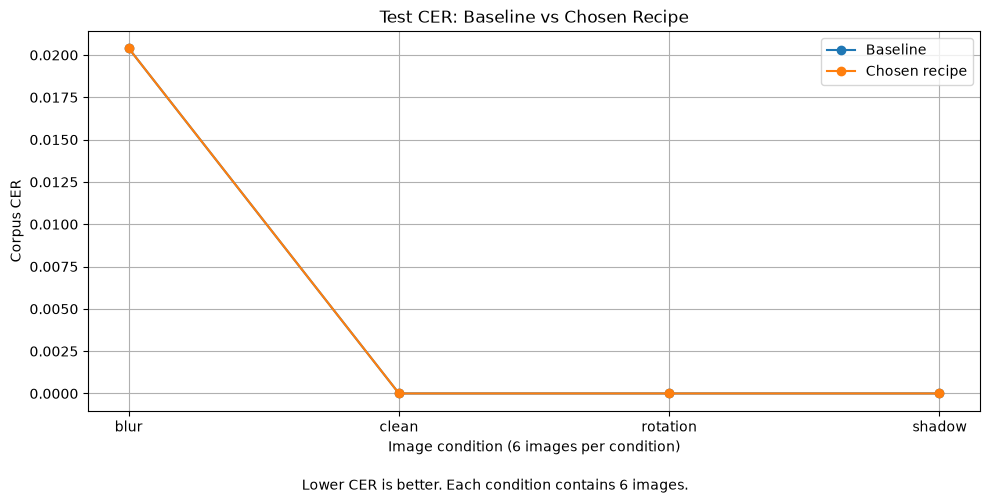

In [126]:
import matplotlib.pyplot as plt

# Create summary tables for test results
test_base_table = make_summary(test_baseline_results)
test_chosen_table = make_summary(test_chosen_results)

# Remove Overall row
test_base_table = test_base_table[
    test_base_table['Condition'] != 'Overall'
]

test_chosen_table = test_chosen_table[
    test_chosen_table['Condition'] != 'Overall'
]

# Prepare chart
conditions = test_base_table['Condition'].tolist()

baseline_cer = test_base_table['Corpus CER'].tolist()
chosen_cer = test_chosen_table['Corpus CER'].tolist()

plt.figure(figsize=(10, 5))

plt.plot(
    conditions,
    baseline_cer,
    marker='o',
    label='Baseline'
)

plt.plot(
    conditions,
    chosen_cer,
    marker='o',
    label='Chosen recipe'
)

plt.xlabel('Image condition (6 images per condition)')
plt.ylabel('Corpus CER')

plt.title('Test CER: Baseline vs Chosen Recipe')
plt.legend()
plt.grid(True)

plt.figtext(
    0.5, 0.01,
    'Lower CER is better. Each condition contains 6 images.',
    ha='center'
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

In [127]:
comparison = test_baseline_results.merge(
    test_chosen_results,
    on='base_id',
    suffixes=('_baseline', '_chosen')
)

# Improvement: fewer edits
improvements = comparison[
    comparison['edits_chosen'] < comparison['edits_baseline']
]

# Unchanged: same number of edits
unchanged = comparison[
    comparison['edits_chosen'] == comparison['edits_baseline']
]

# Regression: more edits
regressions = comparison[
    comparison['edits_chosen'] > comparison['edits_baseline']
]

print("Improvements:", len(improvements))
print("Unchanged:", len(unchanged))
print("Regressions:", len(regressions))

Improvements: 3
Unchanged: 90
Regressions: 3


In [128]:
example_improvement = (
    improvements.iloc[0] if len(improvements) > 0 else None
)

example_unchanged = (
    unchanged.iloc[0] if len(unchanged) > 0 else None
)

example_regression = (
    regressions.iloc[0] if len(regressions) > 0 else None
)

Improvement: The image has low contrast, and some characters are difficult to distinguish from the background. I think the preprocessing improved the contrast and helped OCR recognize the characters more accurately.

Regression: The image has small and thin characters. I think the preprocessing removed some important details or changed the character shapes, which made OCR recognition worse.

### Recommendation

I recommend keeping fix_a because it achieved a lower Corpus CER on the validation data than fix_b (0.0053 vs 0.25). fix_b failed completely on shadow images (CER 1.00, 0 of 6 exact matches).

However, fix_a did not improve on the baseline: on the test set both have Corpus CER 0.0051 and 23 of 24 exact matches. Blur is still the most difficult condition for OCR: it is the only condition where the baseline and fix_a make mistakes.

Our dataset contains only 48 synthetic images. It is a small dataset and cannot represent all real-world situations. Real product labels may have different lighting, backgrounds, angles, fonts and image quality. Therefore, we need more real images to understand how well the system works in practice.